# Synthetic 3dBox study with production data

This notebook runs a complete **synthetic** history-matching study with APEX on the 3dBox case (60×60×5 cells of 30 m, three water injectors and three producers, OPM Flow):

1. check the case: the true model's data (the wells' oil and water rates and water injection rates, 1,197 data) written by `prepare.py`, and the four configurations;
2. history-match the **log-permeability and the porosity** of every cell (36,000 unknowns, 100 members) with ES-MDA (4 steps, α = 4) and GIES/RLM-MAC (at most 10 iterations), each with and without adaptive localization (`adaptive_prior` with the fixed threshold 3/√N = 0.3);
3. tabulate the prior and final metrics: normalized data mismatch, RMSE and SSIM of both variables against the true model, and the spread kept; and the same at every kept iteration of each experiment;
4. plot the results.

The same case with AVO maps as well is `examples/3dbox_production_avo`: the same deck, prior and rates.

Run it from `examples/3dbox_production/` with OPM Flow on `PATH`. The four runs take a couple of hours on 10 cores; existing results in `results/` are reused.

In [1]:
import sys
from pathlib import Path

from IPython.display import Image, Markdown, display

HERE = Path.cwd()  # run from examples/3dbox_production/
sys.path.insert(0, str(HERE))
import synthetic_demo as demo  # noqa: E402

FONT_SIZE = 12  # of every figure

## 1. The case

`prepare.py` ran the true model once and wrote the observations: each rate with a standard deviation of 10 % of its value, at least 8 sm³/day. Each configuration's plan, as `apex validate` gives it (nothing is simulated):

In [2]:
for name, (label, _) in demo.EXPERIMENTS.items():
    print(f"{label:26} {demo.plan(name)}")
print()
print((HERE / "config_gies.toml").read_text())

ES-MDA                     esmda, 100 members, 36000 unknowns, 1197 data; at most 5 forecasts, 500 simulations
GIES                       gies, 100 members, 36000 unknowns, 1197 data; at most 11 forecasts, 1121 simulations
ES-MDA, no localization    esmda, 100 members, 36000 unknowns, 1197 data; at most 5 forecasts, 500 simulations
GIES, no localization      gies, 100 members, 36000 unknowns, 1197 data; at most 11 forecasts, 1121 simulations

# The 3dBox case, written by prepare.py: GIES (RLM-MAC, 10 iterations) on the wells' rates, on OPM Flow; the
# log-permeability and the porosity are uncertain.
[run]
name = "3dbox_production_gies"
seed = 2026

[[state.variables]]
name = "permx"   # ln PERMX (mD); the deck caps it at permx_cap
size = 18000
grid = [60, 60, 5]
lower = -3.0     # bounds just outside the truth's -2.2 ... 6.9: members are clipped to them
upper = 10.0

[[state.variables]]
name = "poro"
size = 18000
grid = [60, 60, 5]
lower = 0.01
upper = 0.4

[prior]   # 100 members draw

## 2. History matching

Each experiment writes its run directory to `results/<experiment>/`: per step the ensemble and its forecast (`checkpoints/iter_<k>.npz`), the per-member data mismatch and metrics (`data_mismatch_<k>.npz`), the history and a summary. Existing results are kept (pass `rerun=True` to recompute them).

In [3]:
runs = demo.run_experiments()
results = demo.load_results(runs)
for name, run in results.items():
    label = demo.EXPERIMENTS[name][0]
    print(f"{label:26} forecasts: {len(run.history):2}  kept: {run.accepted_iterations}")

ES-MDA                     forecasts:  5  kept: [0, 1, 2, 3, 4]
GIES                       forecasts: 11  kept: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
ES-MDA, no localization    forecasts:  5  kept: [0, 1, 2, 3, 4]
GIES, no localization      forecasts: 11  kept: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


## 3. Final metrics

Member means at the prior and the final iterate (the mismatch is the normalized data mismatch). **Spread** is the posterior standard deviation over the prior's, averaged over the cells.

In [4]:
demo.write_table(results)  # results/comparison/final_metrics.csv
rows = [demo.summary_row(name, run) for name, run in results.items()]
columns = {"mismatch all": "normalized_data_mismatch_all"}
columns |= {f"mismatch {t}": f"normalized_data_mismatch_{t}" for t in demo.FIELD_TYPES}
for variable in demo.VARIABLES:
    columns[f"RMSE {variable}"] = f"rmse_{variable}"
    columns[f"SSIM {variable}"] = f"ssim_{variable}"
spreads = {f"spread {v}": f"spread_{v}" for v in demo.VARIABLES}


summary = [
    {"": "prior"}
    | {c: rows[0][k + "_prior"] for c, k in columns.items()}
    | dict.fromkeys(spreads, 1.0)
]
for row in rows:
    summary.append(
        {"": row["experiment"]}
        | {c: row[k + "_final"] for c, k in columns.items()}
        | {c: row[k] for c, k in spreads.items()}
    )
display(Markdown(demo.markdown_table(summary)))

|  | mismatch all | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|
| prior | 4.91e+05 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| ES-MDA | 7.307e+04 | 1.563 | 0.2856 | 0.08443 | 0.1547 | 1.028 | 0.9934 |
| GIES | 1.621e+05 | 1.335 | 0.3271 | 0.08175 | 0.1612 | 0.9947 | 0.9982 |
| ES-MDA, no localization | 7.109e+05 | 4.286 | 0.0183 | 0.1769 | 0.01217 | 0.3261 | 0.1713 |
| GIES, no localization | 9.421e+04 | 1.56 | 0.2926 | 0.0901 | 0.1431 | 0.9158 | 0.929 |

### 3.1 Metrics at each iteration

The same member means at every kept iteration of each experiment (iteration 0 is the prior; GIES keeps only its accepted iterations), with the spread kept at that iteration. The tables are also written to `results/comparison/metrics_by_iteration_<experiment>.csv`.

In [5]:
tables = demo.write_iteration_tables(results)
for name, rows in tables.items():
    table = demo.markdown_table(rows)
    display(Markdown(f"**{demo.EXPERIMENTS[name][0]}**\n\n{table}"))

**ES-MDA**

| iteration | mismatch all | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 4.91e+05 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 1.267e+05 | 1.437 | 0.3013 | 0.08375 | 0.1506 | 1.014 | 0.9999 |
| 2 | 1.299e+05 | 1.519 | 0.2922 | 0.08393 | 0.153 | 1.019 | 0.9979 |
| 3 | 1.453e+05 | 1.575 | 0.2857 | 0.08469 | 0.154 | 1.023 | 0.9944 |
| 4 | 7.307e+04 | 1.563 | 0.2856 | 0.08443 | 0.1547 | 1.028 | 0.9934 |

**GIES**

| iteration | mismatch all | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 4.91e+05 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 2.469e+05 | 1.331 | 0.3287 | 0.08203 | 0.1573 | 0.9971 | 0.9991 |
| 2 | 2.093e+05 | 1.331 | 0.3291 | 0.08192 | 0.159 | 0.9962 | 0.9988 |
| 3 | 1.925e+05 | 1.332 | 0.3289 | 0.08185 | 0.1599 | 0.9957 | 0.9987 |
| 4 | 1.837e+05 | 1.333 | 0.3285 | 0.08181 | 0.1604 | 0.9954 | 0.9986 |
| 5 | 1.778e+05 | 1.333 | 0.3282 | 0.08179 | 0.1606 | 0.9952 | 0.9985 |
| 6 | 1.734e+05 | 1.334 | 0.3279 | 0.08178 | 0.1608 | 0.9951 | 0.9985 |
| 7 | 1.699e+05 | 1.334 | 0.3277 | 0.08177 | 0.1609 | 0.9949 | 0.9984 |
| 8 | 1.669e+05 | 1.335 | 0.3275 | 0.08176 | 0.1611 | 0.9948 | 0.9983 |
| 9 | 1.644e+05 | 1.335 | 0.3273 | 0.08175 | 0.1612 | 0.9947 | 0.9983 |
| 10 | 1.621e+05 | 1.335 | 0.3271 | 0.08175 | 0.1612 | 0.9947 | 0.9982 |

**ES-MDA, no localization**

| iteration | mismatch all | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 4.91e+05 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 6.225e+05 | 2.466 | 0.1605 | 0.1315 | 0.06241 | 0.8304 | 0.781 |
| 2 | 3.956e+05 | 3.033 | 0.08216 | 0.149 | 0.02746 | 0.6576 | 0.5383 |
| 3 | 2.159e+06 | 3.79 | 0.043 | 0.1655 | 0.04534 | 0.4887 | 0.3168 |
| 4 | 7.109e+05 | 4.286 | 0.0183 | 0.1769 | 0.01217 | 0.3261 | 0.1713 |

**GIES, no localization**

| iteration | mismatch all | RMSE permx | SSIM permx | RMSE poro | SSIM poro | spread permx | spread poro |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 4.91e+05 | 1.345 | 0.3219 | 0.08235 | 0.1531 | 1 | 1 |
| 1 | 2.789e+05 | 1.338 | 0.3283 | 0.08226 | 0.1559 | 0.9806 | 0.9841 |
| 2 | 2.157e+05 | 1.341 | 0.332 | 0.08245 | 0.1593 | 0.9709 | 0.9759 |
| 3 | 1.852e+05 | 1.347 | 0.334 | 0.08267 | 0.1622 | 0.9638 | 0.9702 |
| 4 | 1.667e+05 | 1.356 | 0.3347 | 0.08296 | 0.1644 | 0.9577 | 0.9653 |
| 5 | 1.544e+05 | 1.368 | 0.3341 | 0.08338 | 0.1653 | 0.952 | 0.9607 |
| 6 | 1.448e+05 | 1.386 | 0.3319 | 0.08405 | 0.1646 | 0.9463 | 0.956 |
| 7 | 1.353e+05 | 1.414 | 0.3272 | 0.08509 | 0.1619 | 0.9402 | 0.9507 |
| 8 | 1.227e+05 | 1.452 | 0.3191 | 0.08647 | 0.1571 | 0.9333 | 0.9448 |
| 9 | 1.075e+05 | 1.502 | 0.3074 | 0.08814 | 0.1508 | 0.9253 | 0.9376 |
| 10 | 9.421e+04 | 1.56 | 0.2926 | 0.0901 | 0.1431 | 0.9158 | 0.929 |

## 4. Figures

### 4.1 Metrics over the iterations

The member mean of each metric for the four experiments:

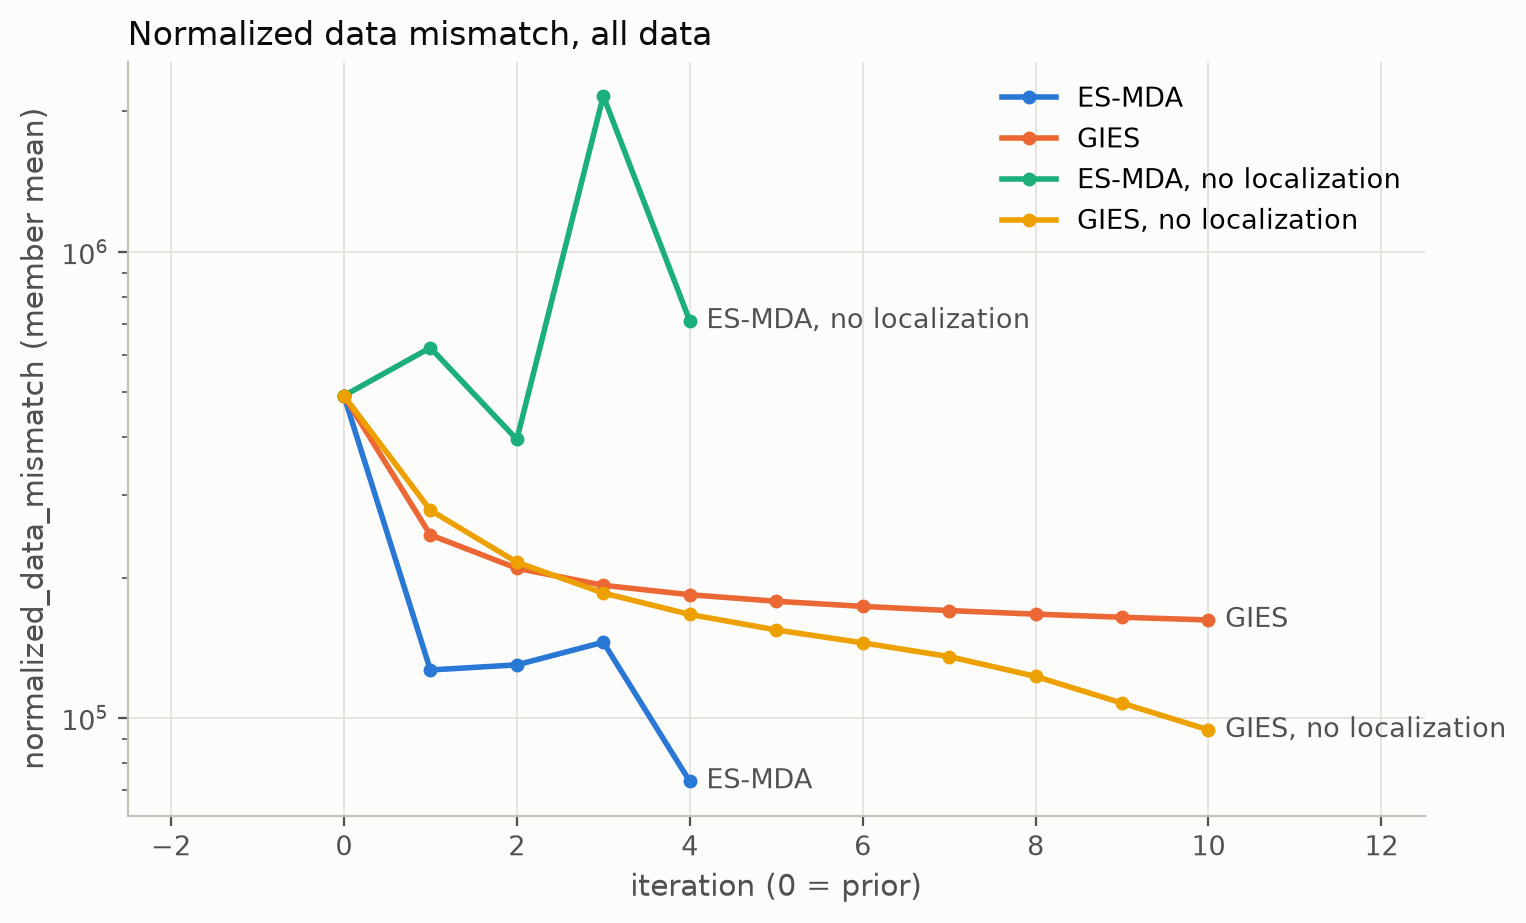

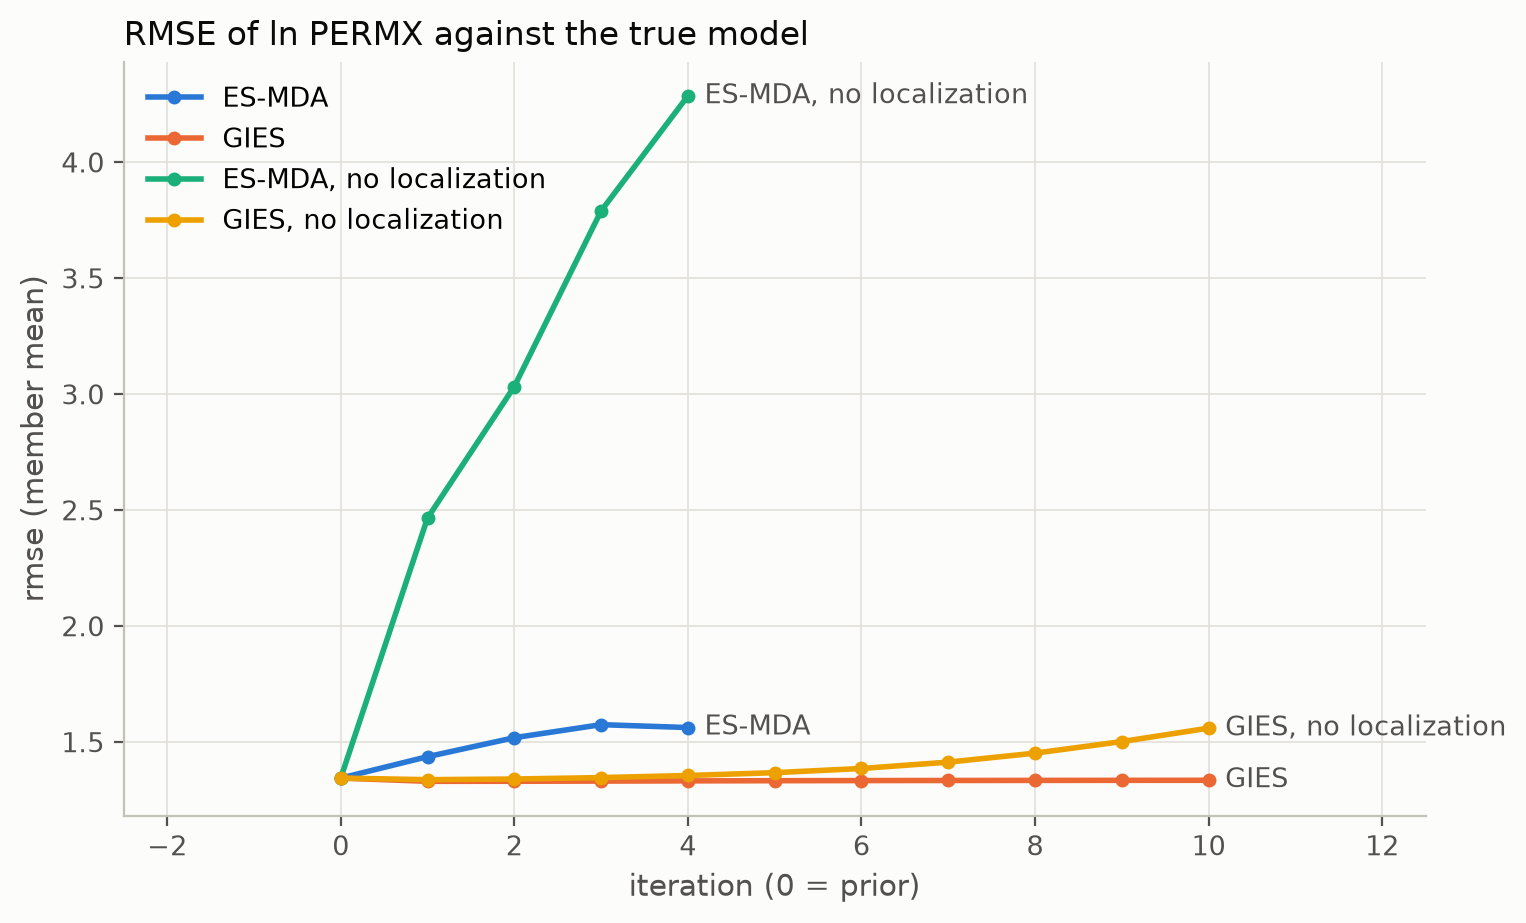

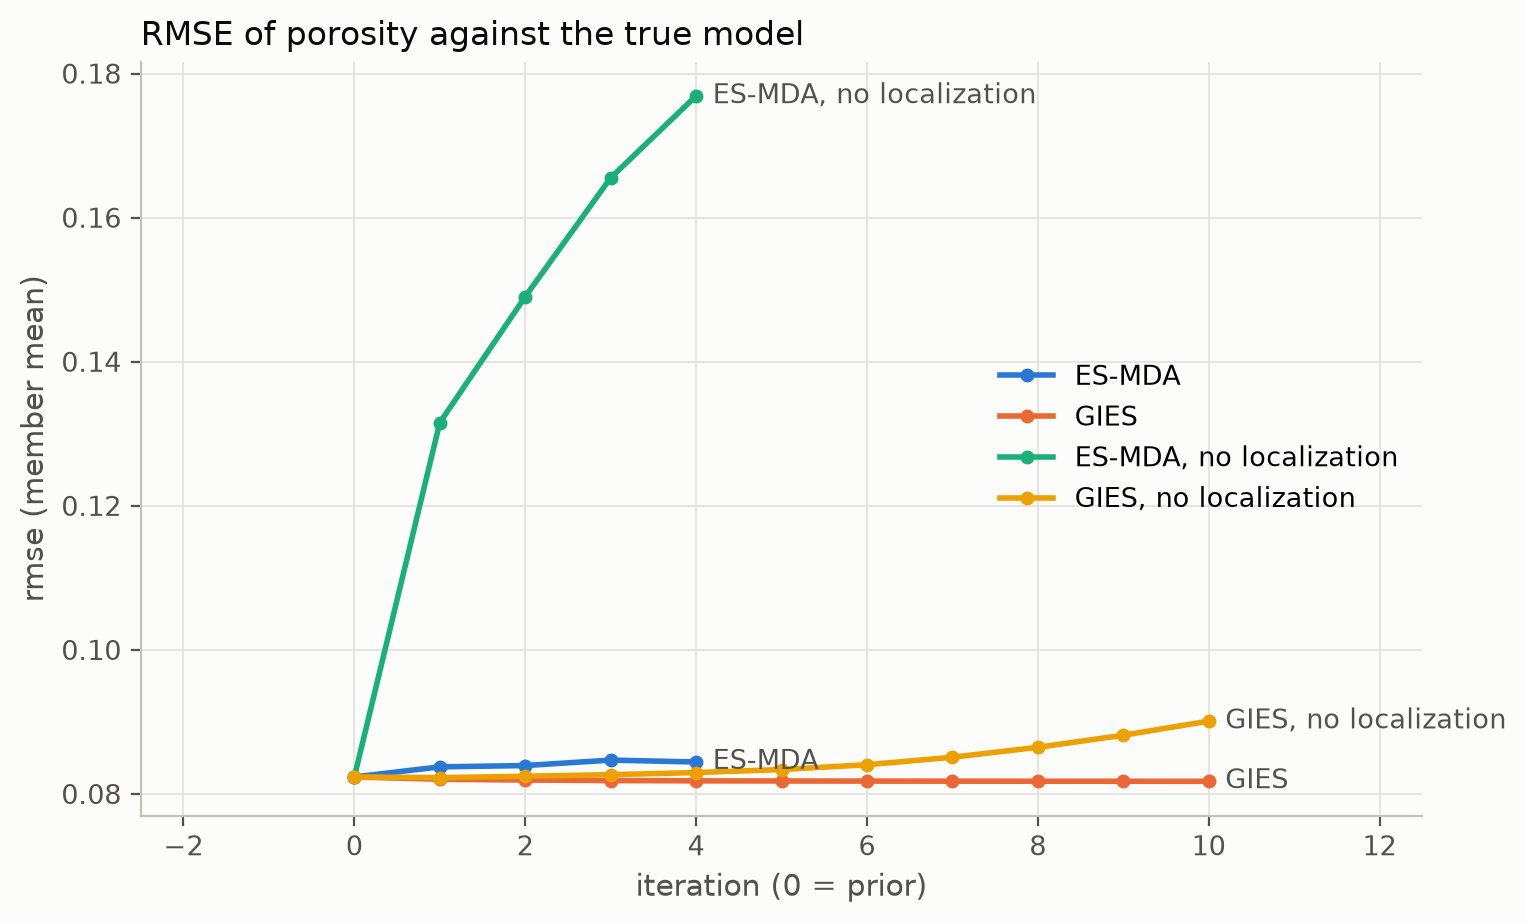

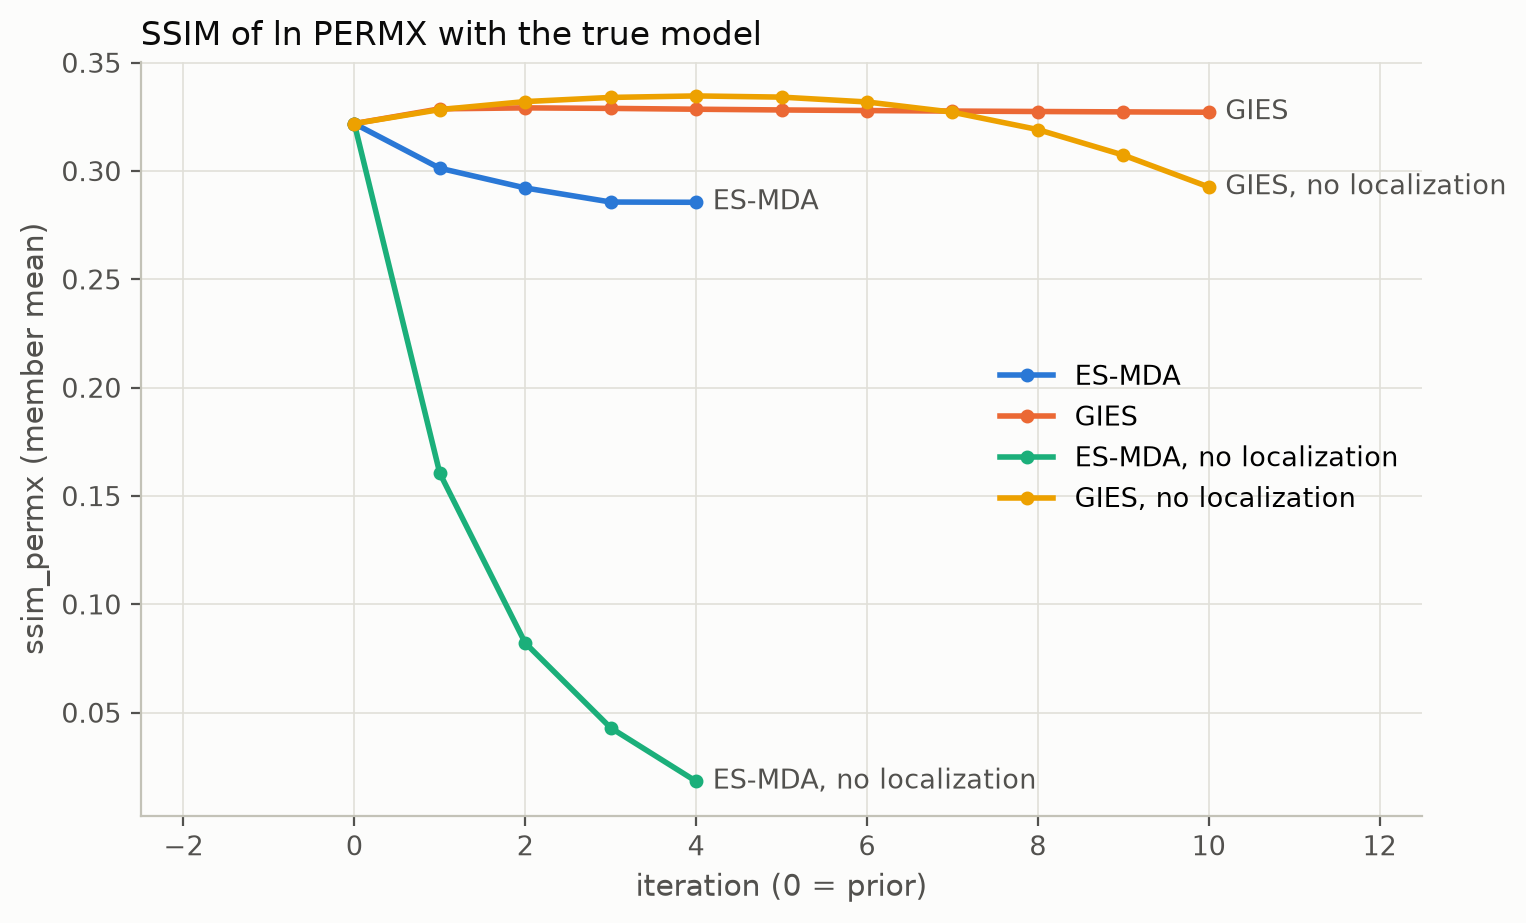

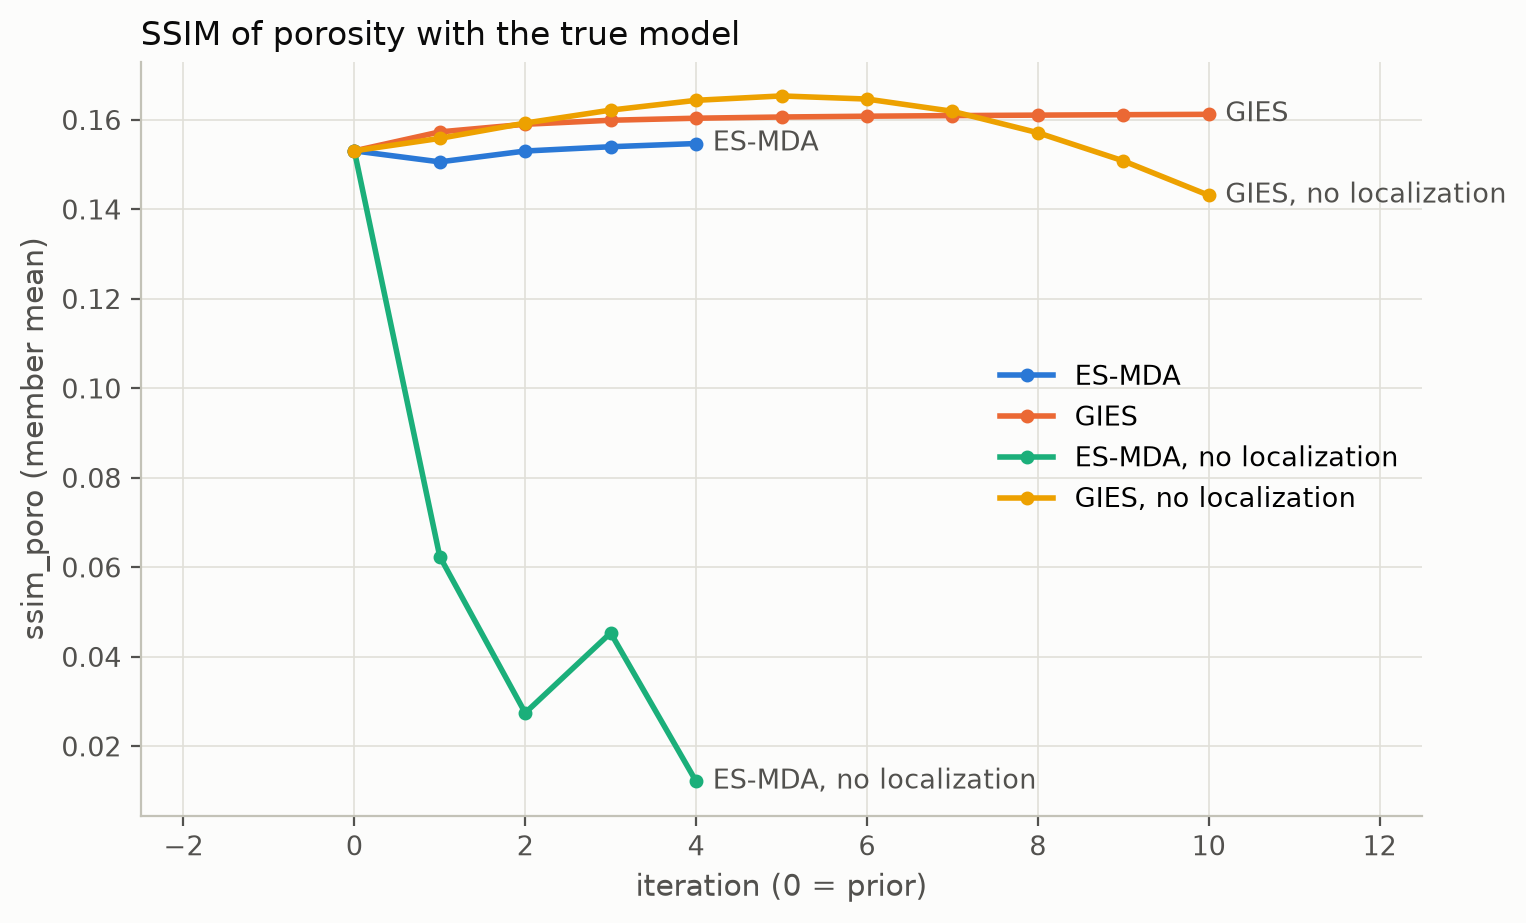

In [6]:
comparison = demo.plot_comparison(results, font_size=FONT_SIZE)
for figure in comparison:
    display(Image(filename=figure.with_suffix(".png"), width=620))

### 4.2 Production data

Per well and data type, the prior and final ensemble forecasts (GIES with localization) against the observations, with the true model's rates:

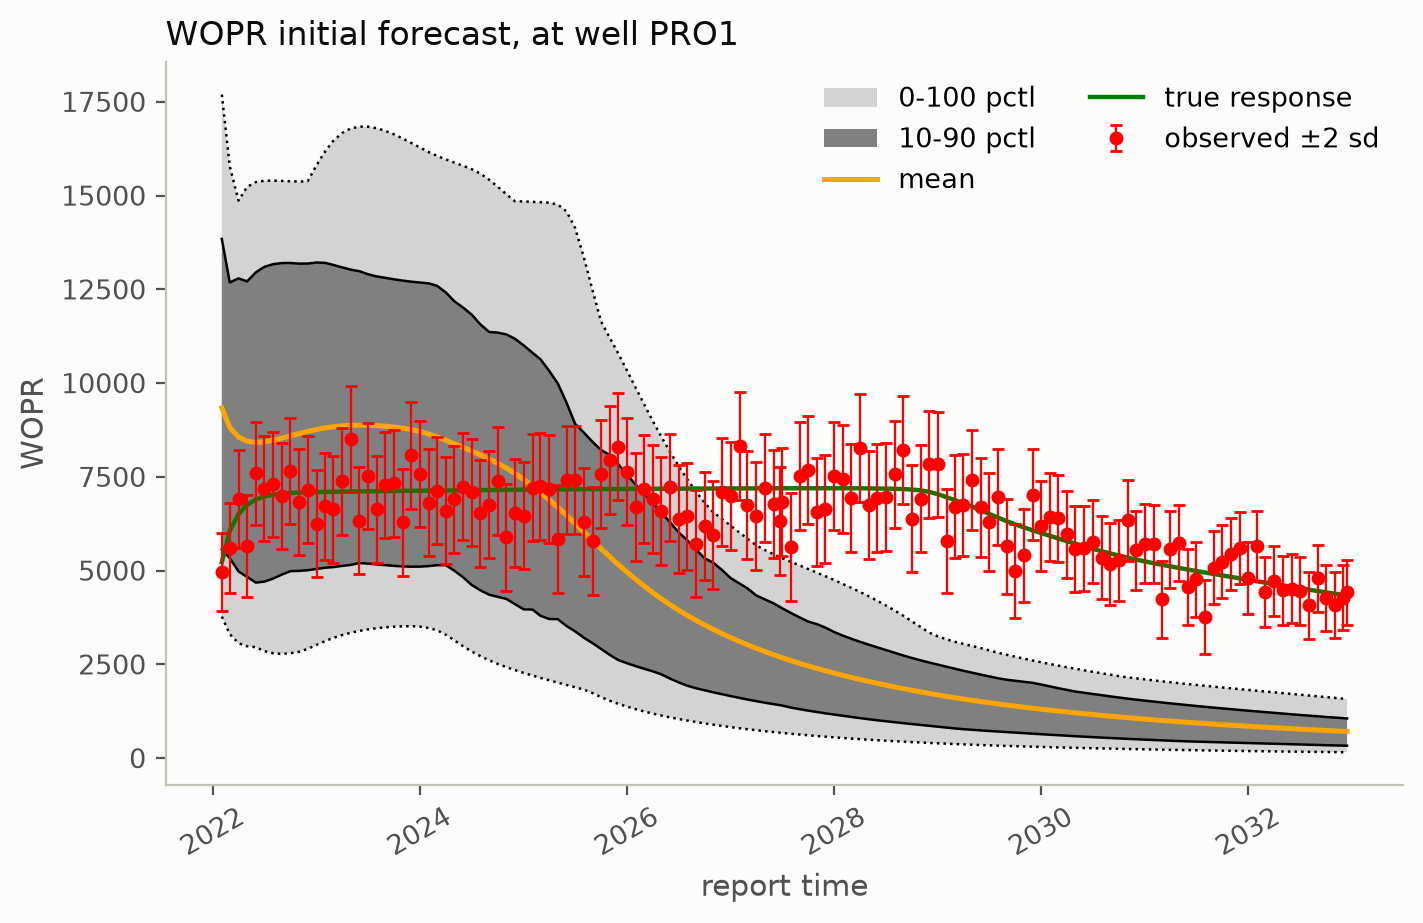

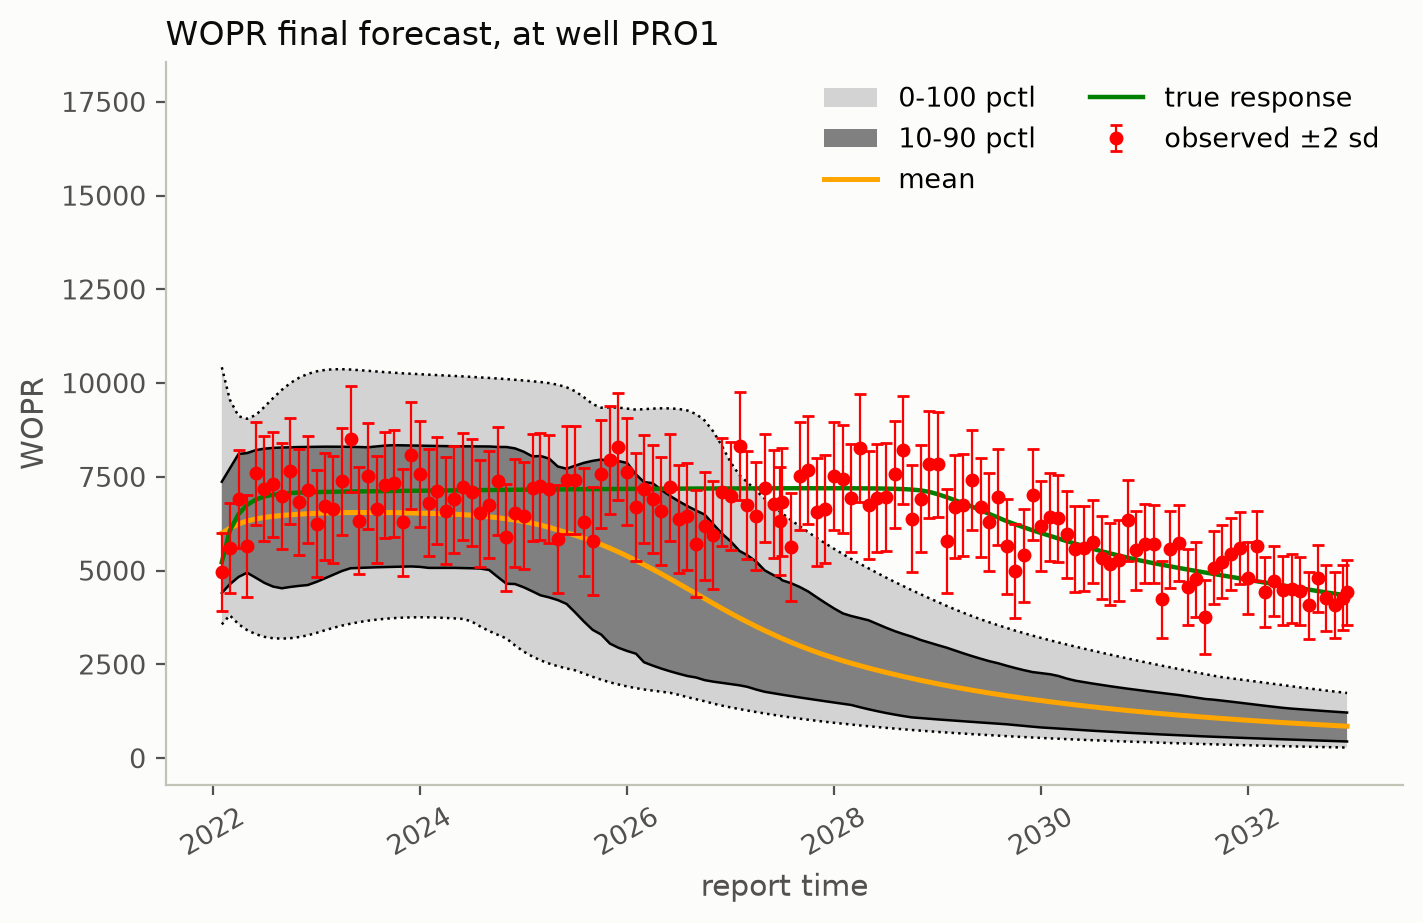

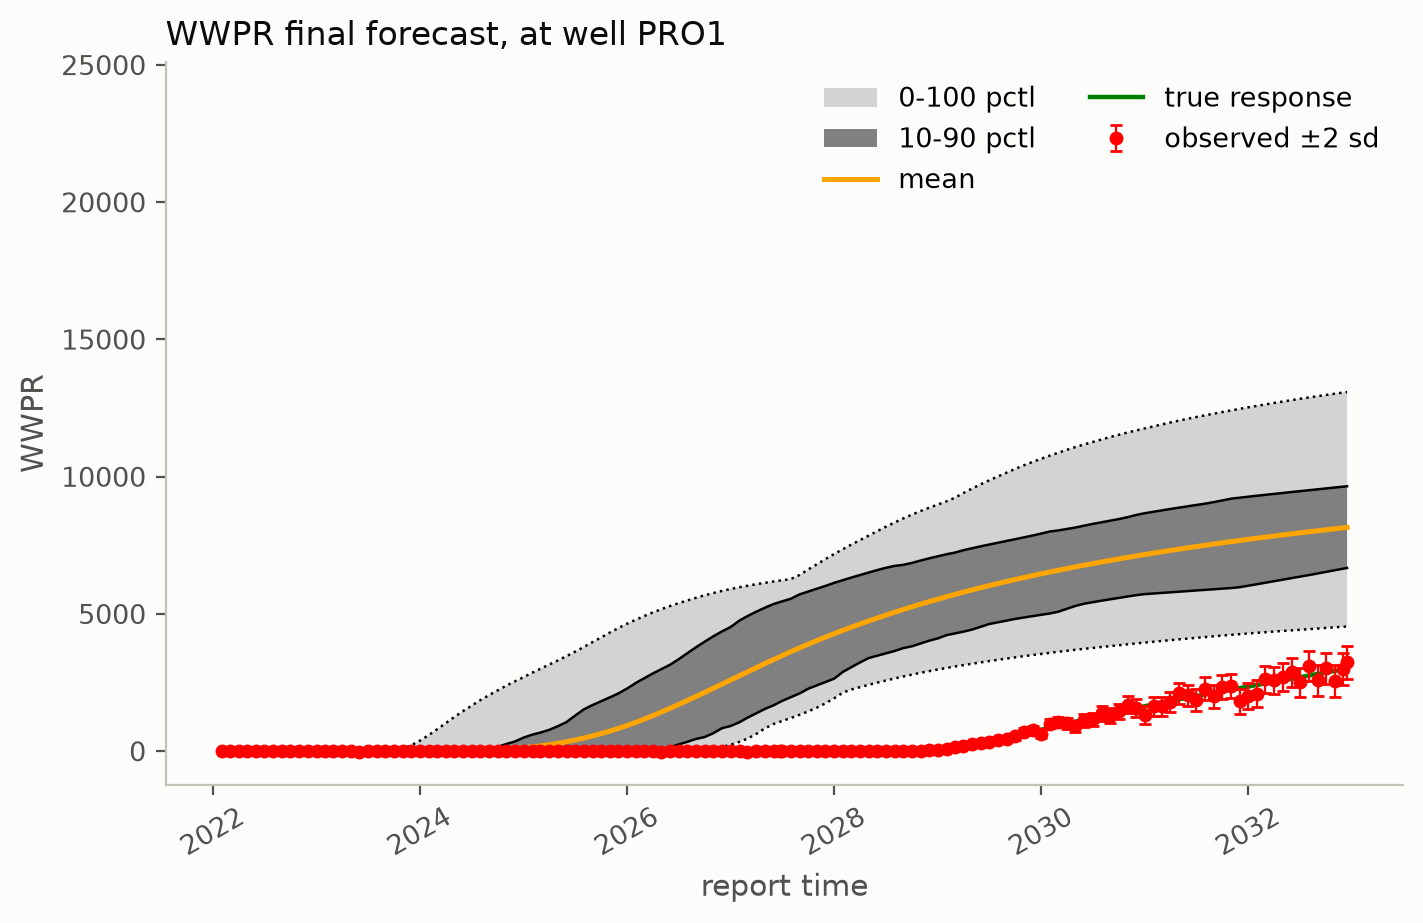

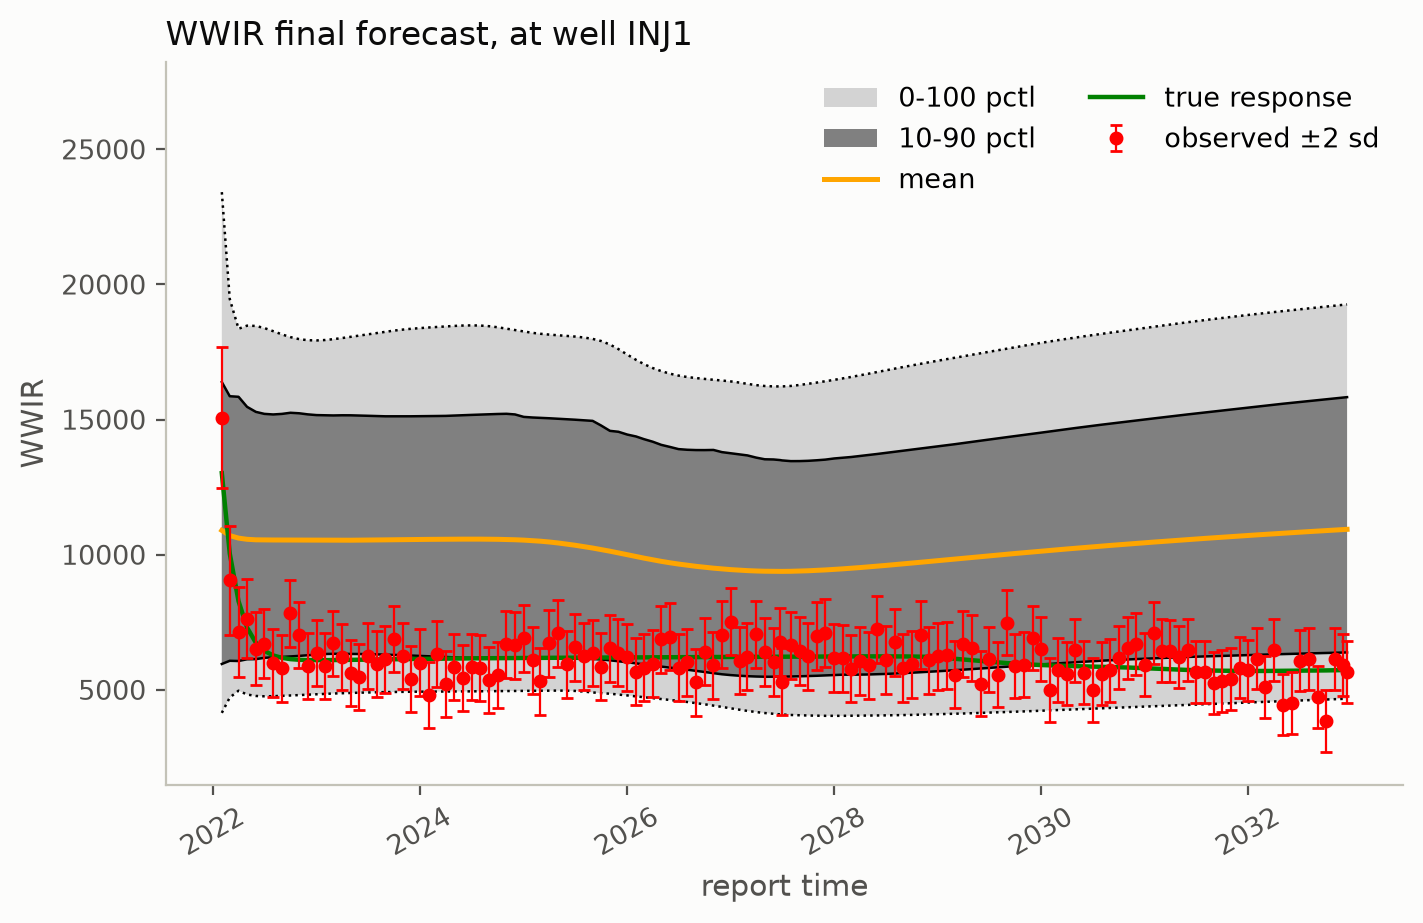

In [7]:
truth = demo.true_response()
reports = {
    name: demo.plot_experiment(path, truth, font_size=FONT_SIZE) for name, path in runs.items()
}
data = runs["gies"] / "report" / "data"
for stem in ("PRO1_WOPR_initial", "PRO1_WOPR_final", "PRO1_WWPR_final", "INJ1_WWIR_final"):
    display(Image(filename=data / f"{stem}.png", width=560))

### 4.3 Parameter fields

Layer 3: the true model, and the final ensemble mean of each experiment, for ln PERMX and porosity (`results/<experiment>/report/fields` has every layer, the means and spreads at the prior and the end, and their differences):

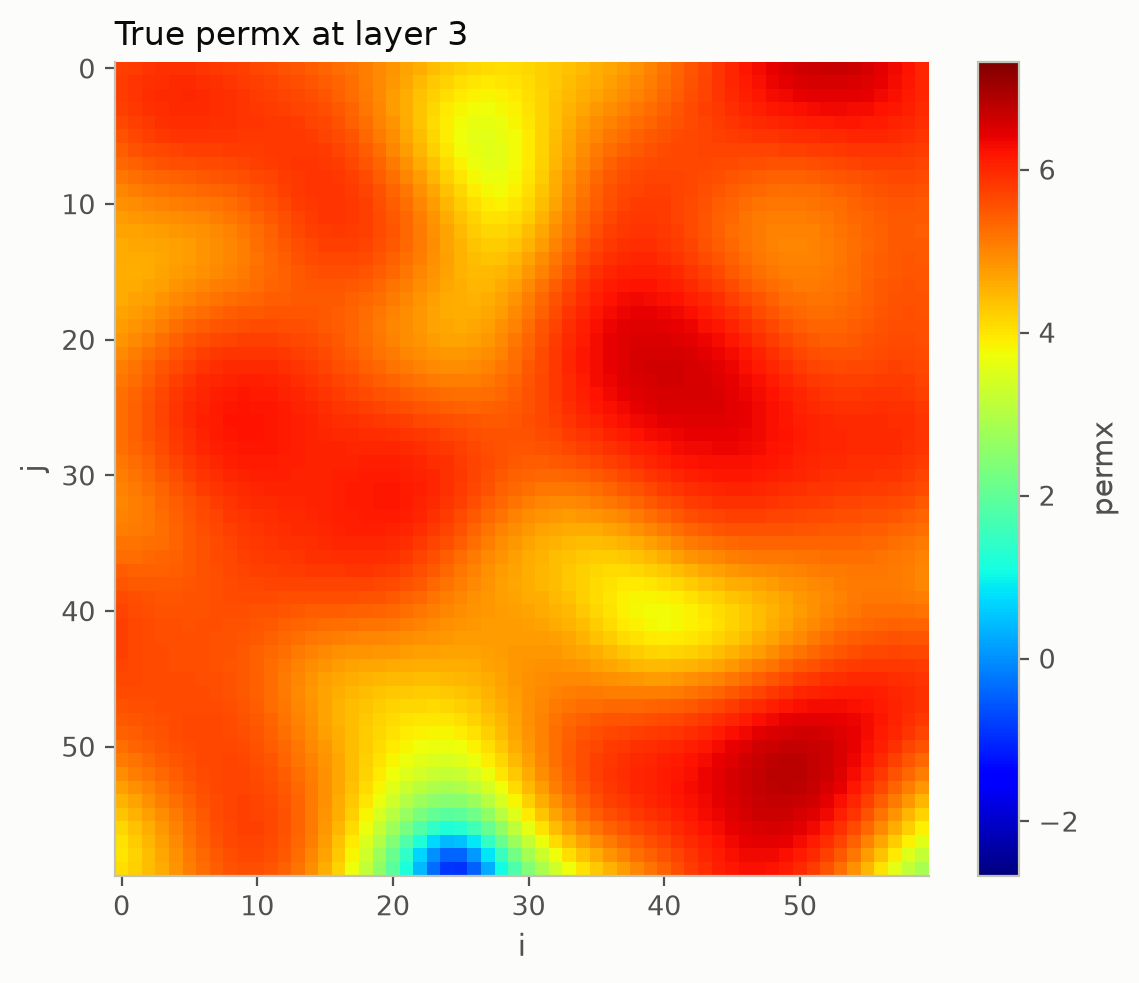

ES-MDA


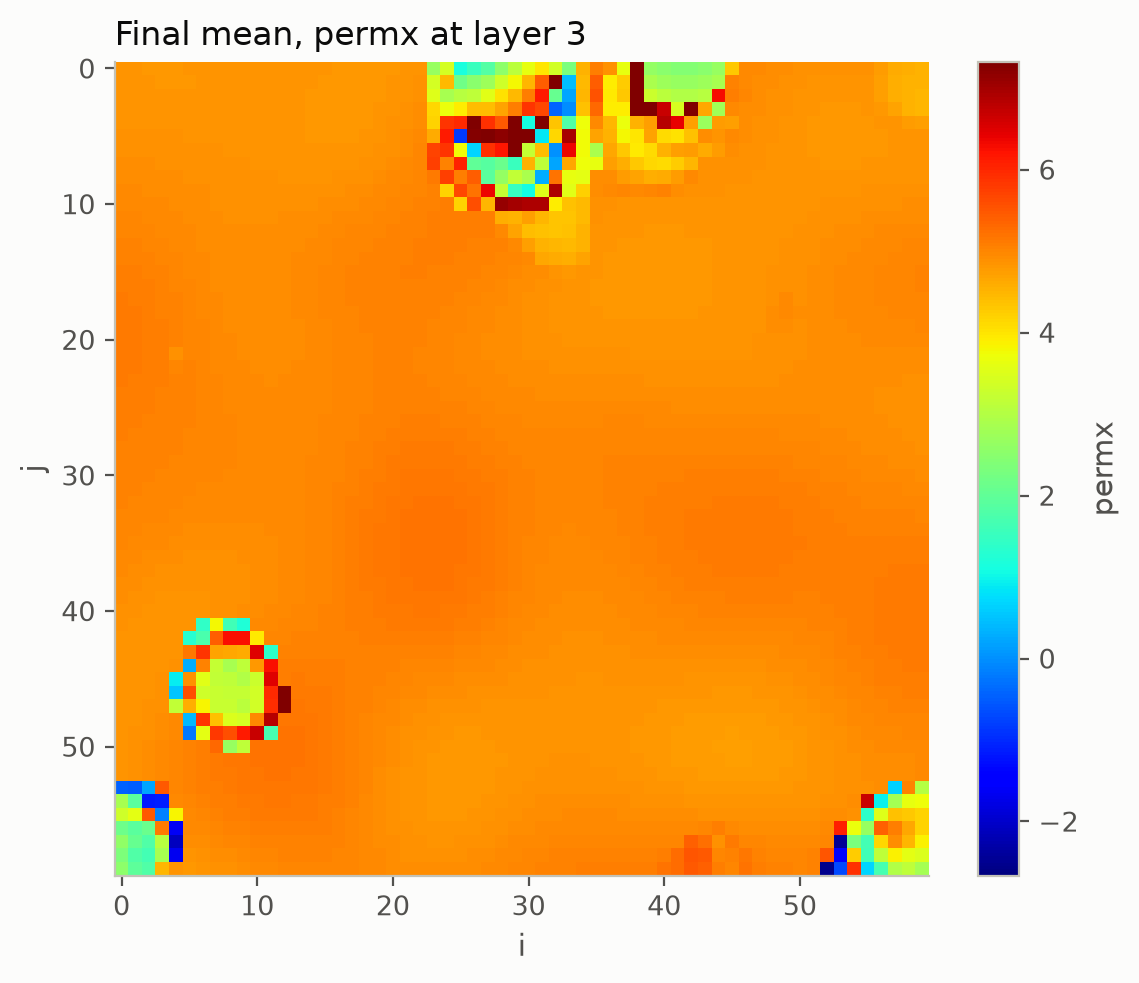

GIES


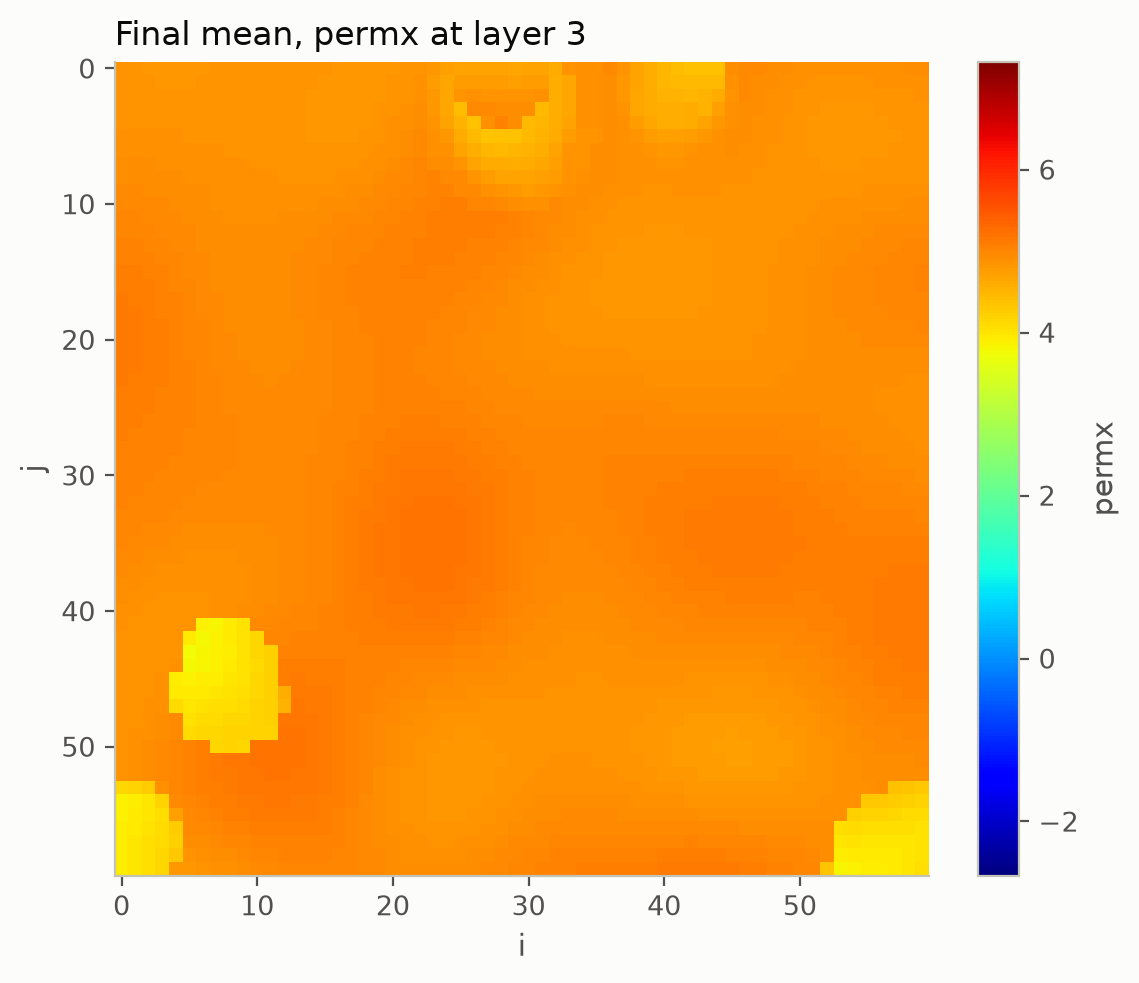

ES-MDA, no localization


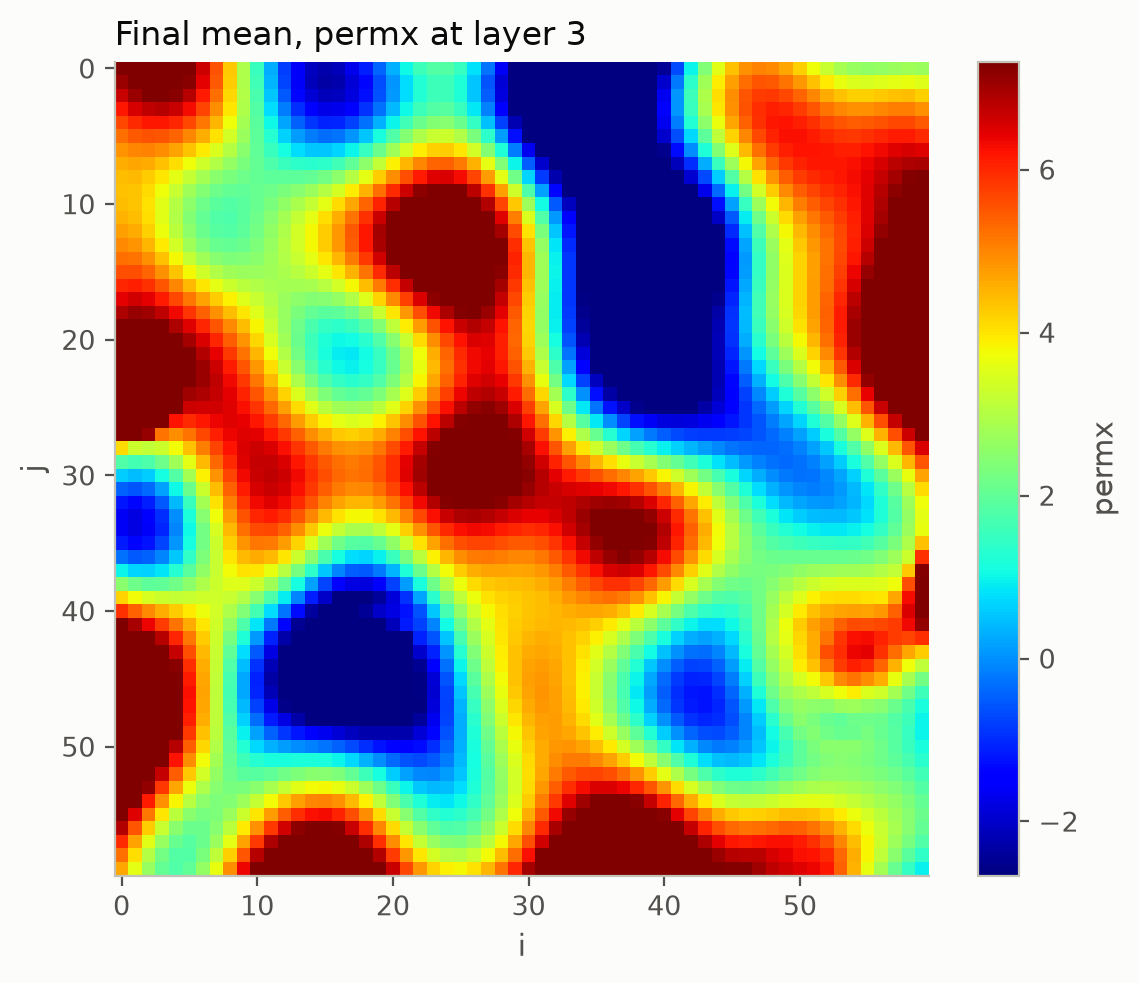

GIES, no localization


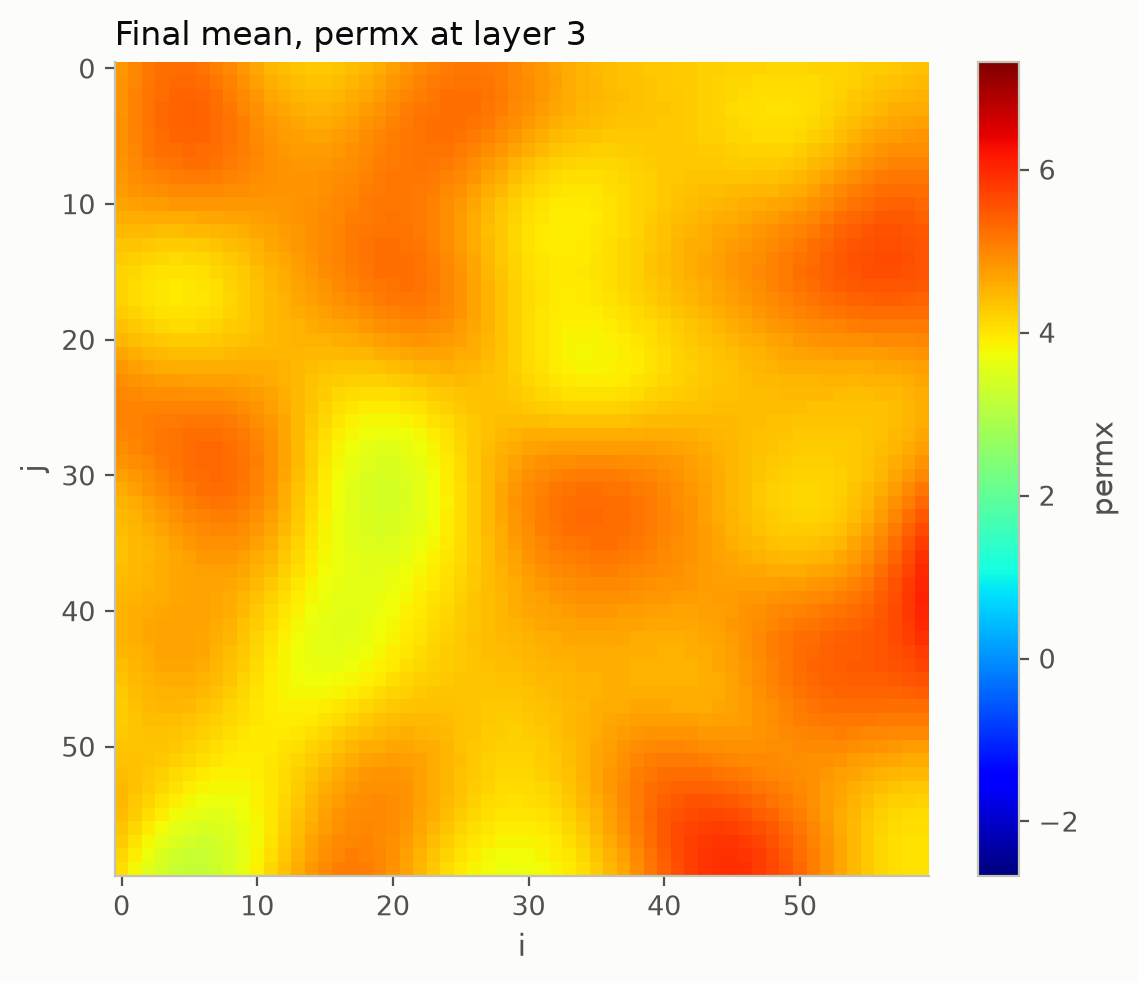

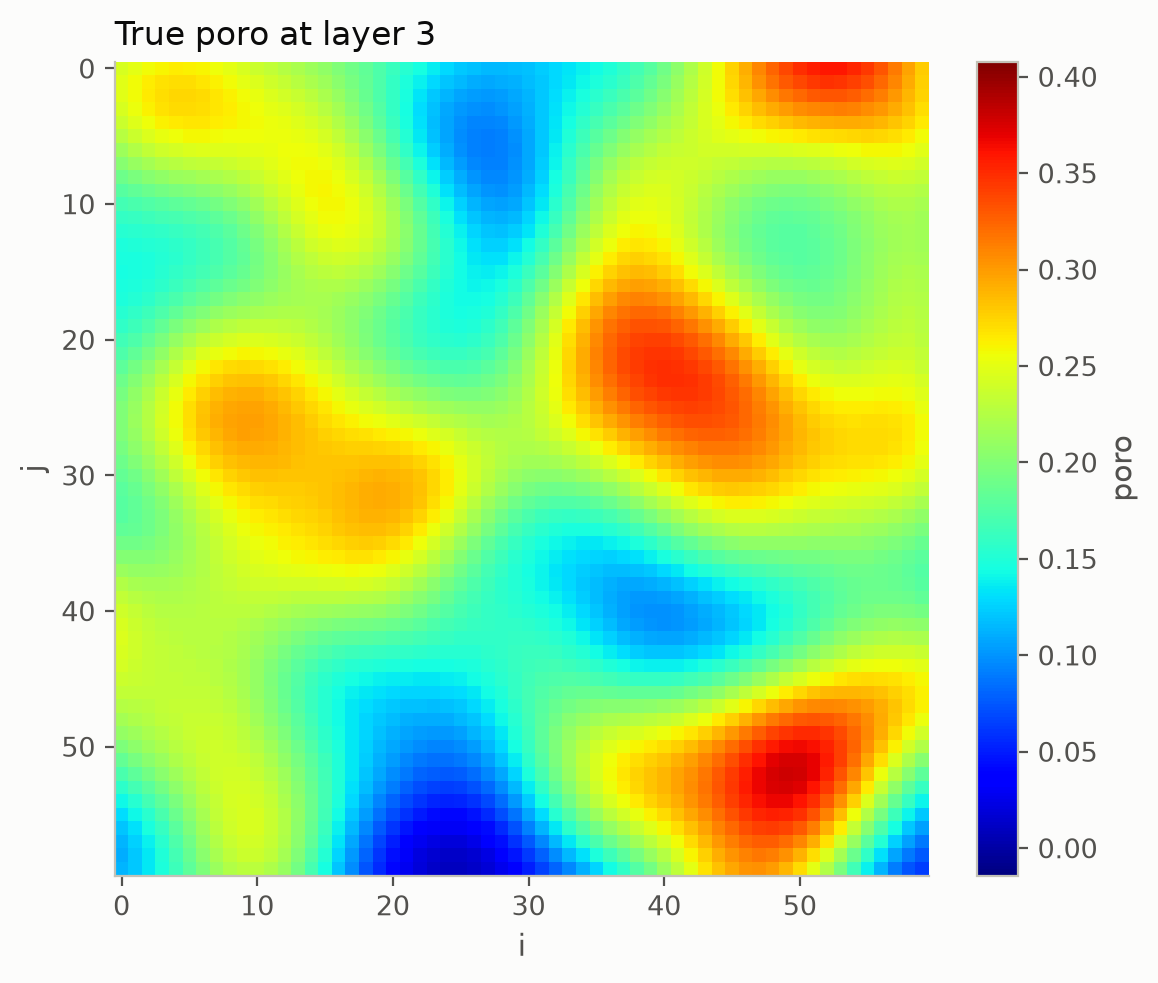

ES-MDA


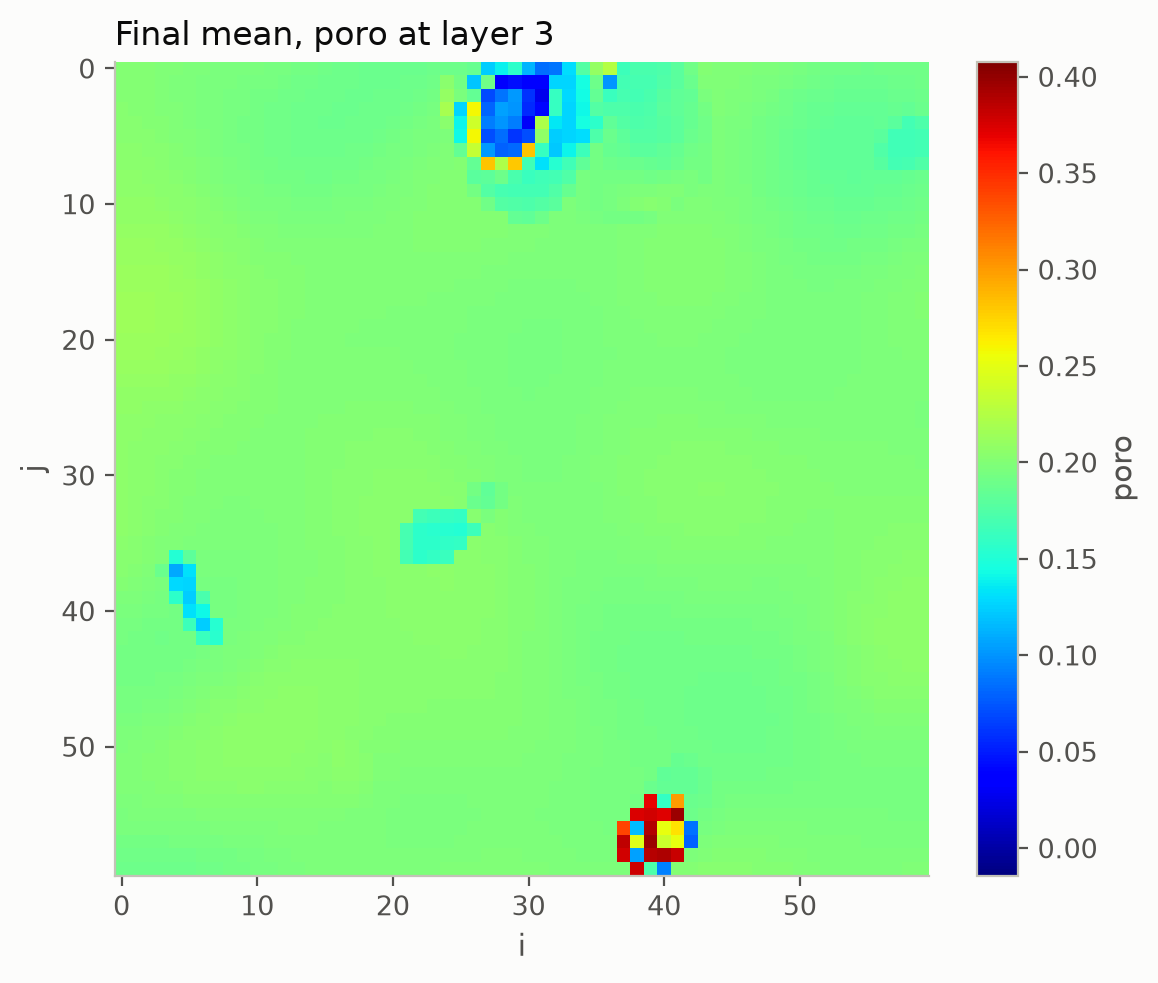

GIES


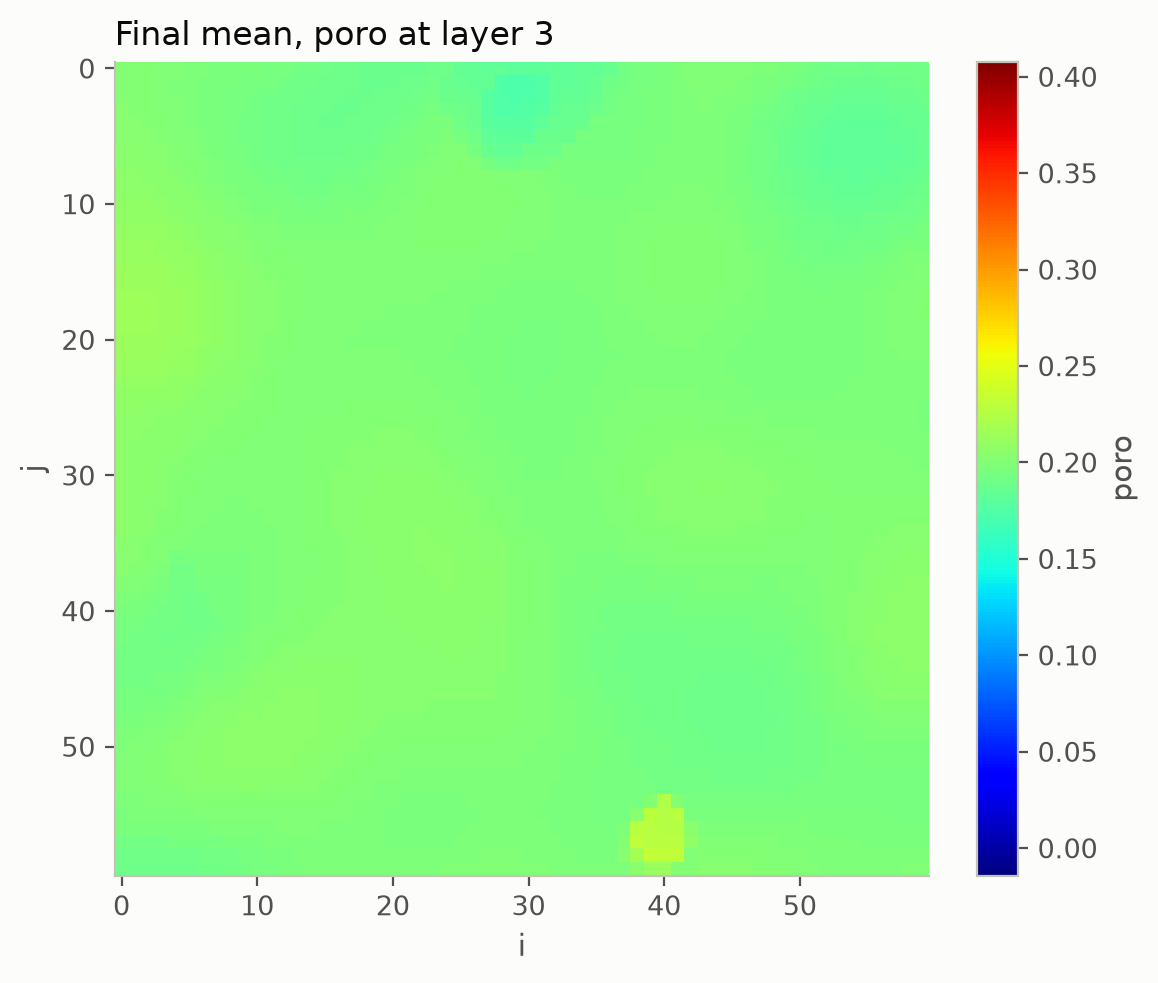

ES-MDA, no localization


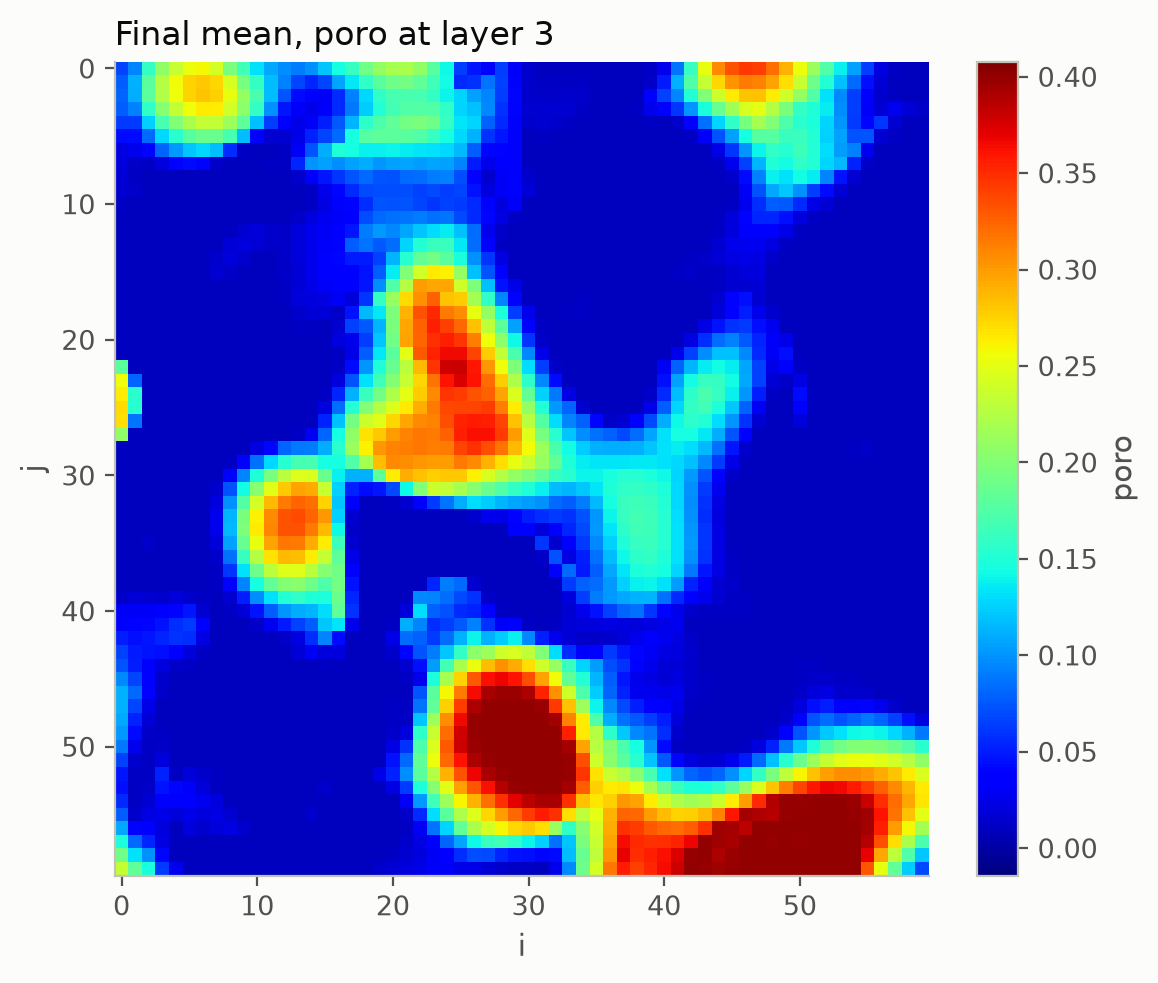

GIES, no localization


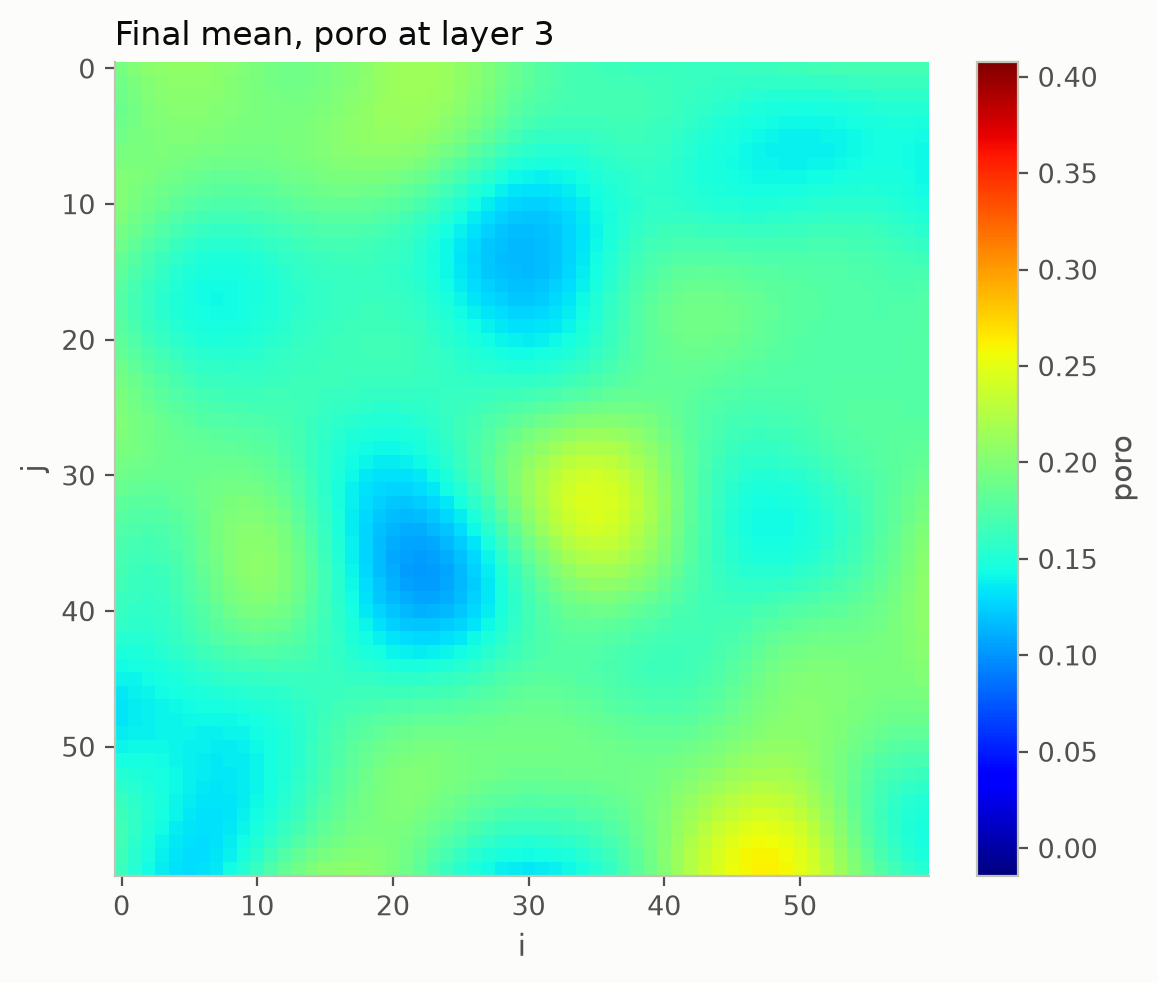

In [8]:
fields = runs["esmda"] / "report" / "fields"
for variable in demo.VARIABLES:
    display(Image(filename=fields / f"{variable}_true_layer3.png", width=420))
    for name in runs:
        print(demo.EXPERIMENTS[name][0])
        display(
            Image(
                filename=runs[name] / "report" / "fields" / f"{variable}_final_mean_layer3.png",
                width=420,
            )
        )

### 4.4 Ensemble spread

The spread of each variable relative to the prior's, over the iterations (GIES with and without localization):

GIES


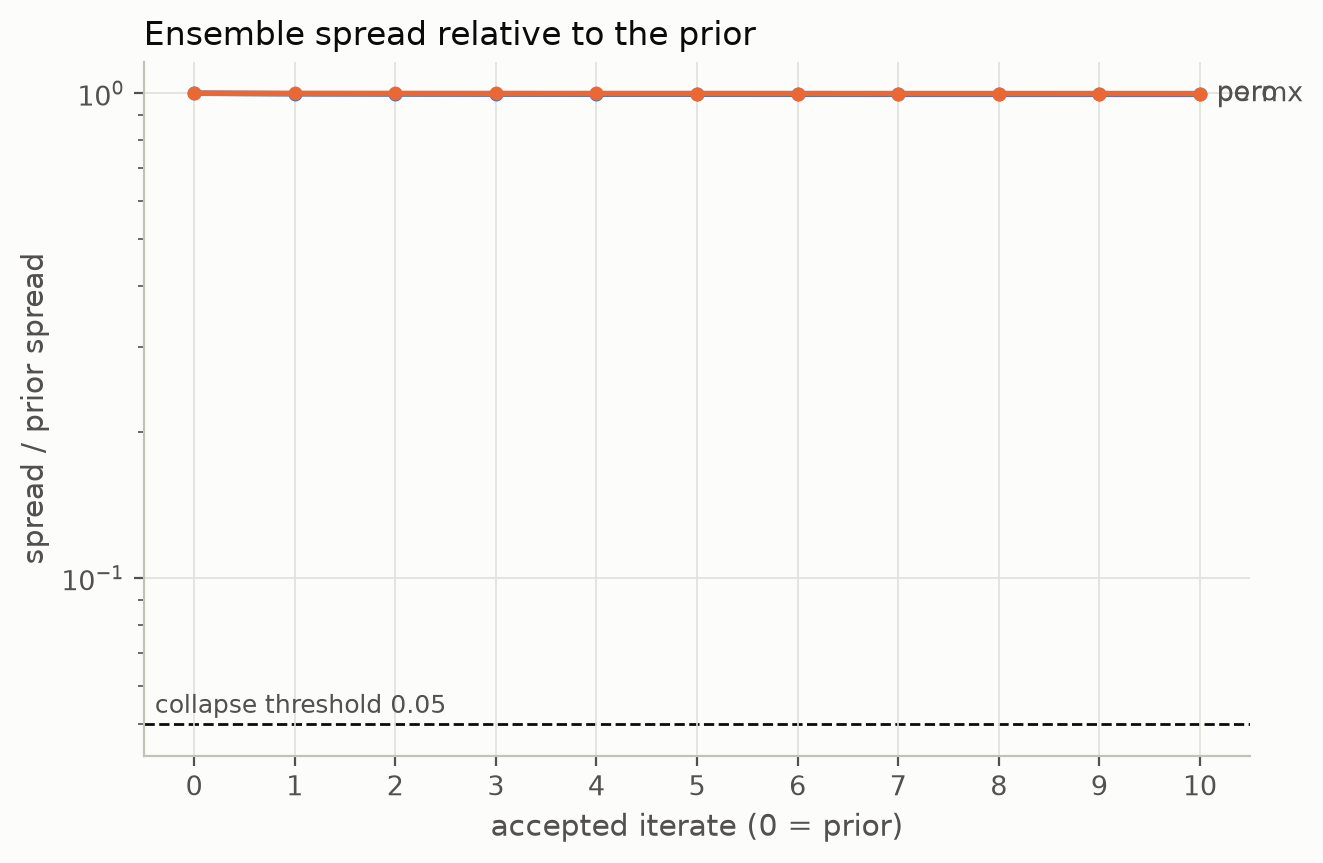

GIES, no localization


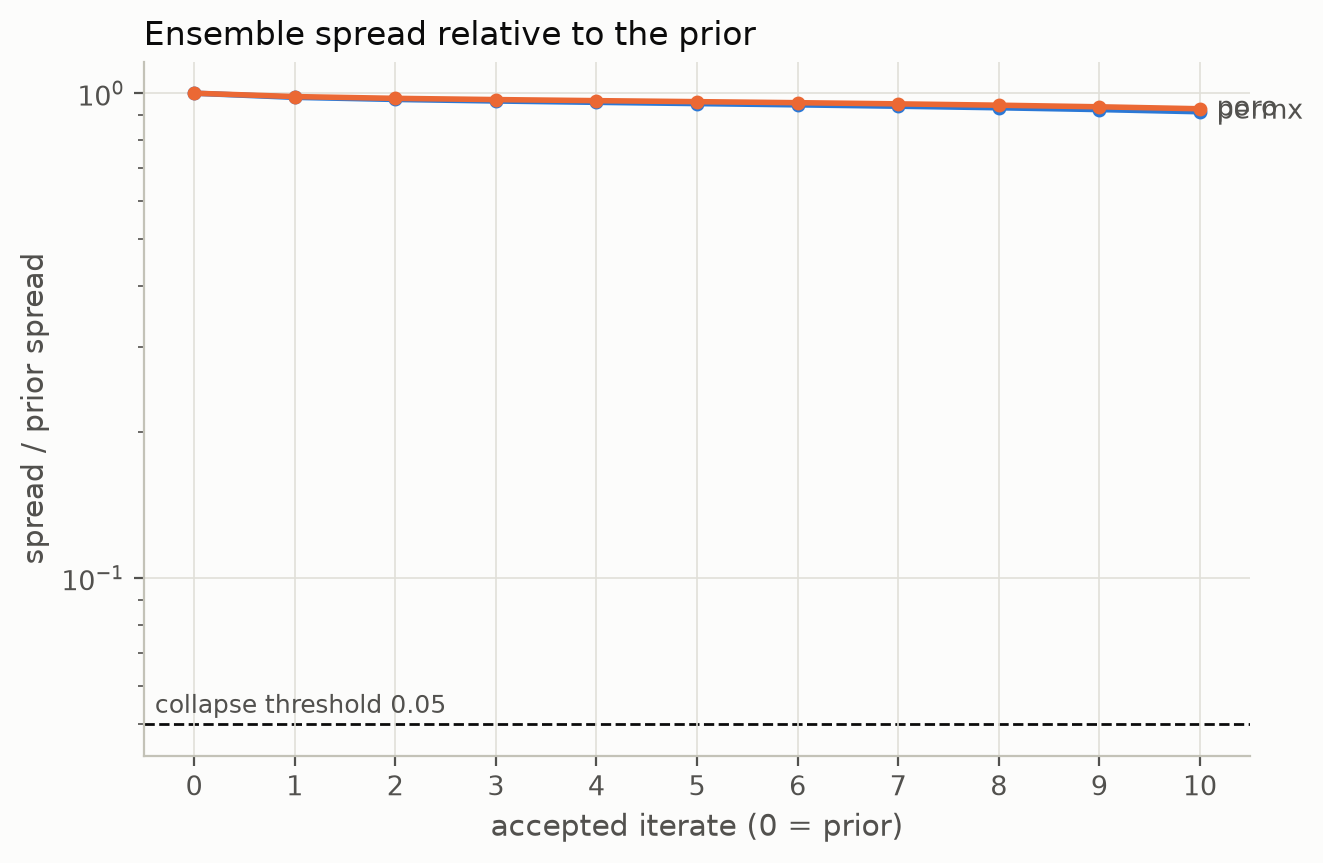

In [9]:
for name in ("gies", "gies_noloc"):
    health = runs[name] / "report" / "health"
    print(demo.EXPERIMENTS[name][0])
    display(Image(filename=health / "spread.png", width=560))